# Synthetic seismic section of a rifted margin from a Mandyoc scenario

Basement and below only (no sediments). Pipeline:

1. Load lithology, temperature, strain and surface from the Mandyoc NetCDF
   outputs, with depths referenced to sea level (the top ``AIR`` metres of
   the box are sticky air).
2. Resample to a fine grid: smooth interface geometry with sharp contacts,
   and water above the seafloor.
3. Density ``rho0 * (1 - alpha * T)`` and Vp per lithology with a
   temperature correction, plus
   * serpentinization of the shallow, cold exhumed mantle;
   * small-scale heterogeneity inside each layer (von Kármán random media;
     laminated in the lower crust), which does not change the geometry;
   * faults from the strain field: where strain is localized (shear bands),
     a damage zone (lower Vp) and a fabric laminated along the band, in the
     brittle domain only.
4. High-frequency convolutional section of the whole window.
5. Zoom with ``tremelique.Acoustic``: exploding-reflector modelling with
   receivers on the seafloor, then reverse-time migration (RTM) with the
   same simulator, displayed in two-way time.

Tremelique only provides acoustic (P-wave) simulation for now, so S waves
are not modelled.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numba
import numpy as np
import scipy.fft
import xarray as xr
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter, gaussian_laplace, uniform_filter1d
from scipy.signal import oaconvolve

import tremelique as tr
from tremelique._acoustic import nonreflexive_bc, timestep_esg
from tremelique._utils import apply_damping

# post_processing folder, with functions/mandyocIO.py (lithology colours of the videos)
sys.path.append(str(Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()))
from functions.mandyocIO import COLOR_WATER, get_lithology_colors  # noqa: E402
from functions.seismic_section_flowchart import plot_flowchart  # noqa: E402

## Flowchart

From the Mandyoc outputs to the seismic sections. The numbers are those of
the sections of this notebook; green steps build the model, orange is the
convolutional section, purple is tremelique, grey is the cache of the zoom
and the outputs.

<Axes: >

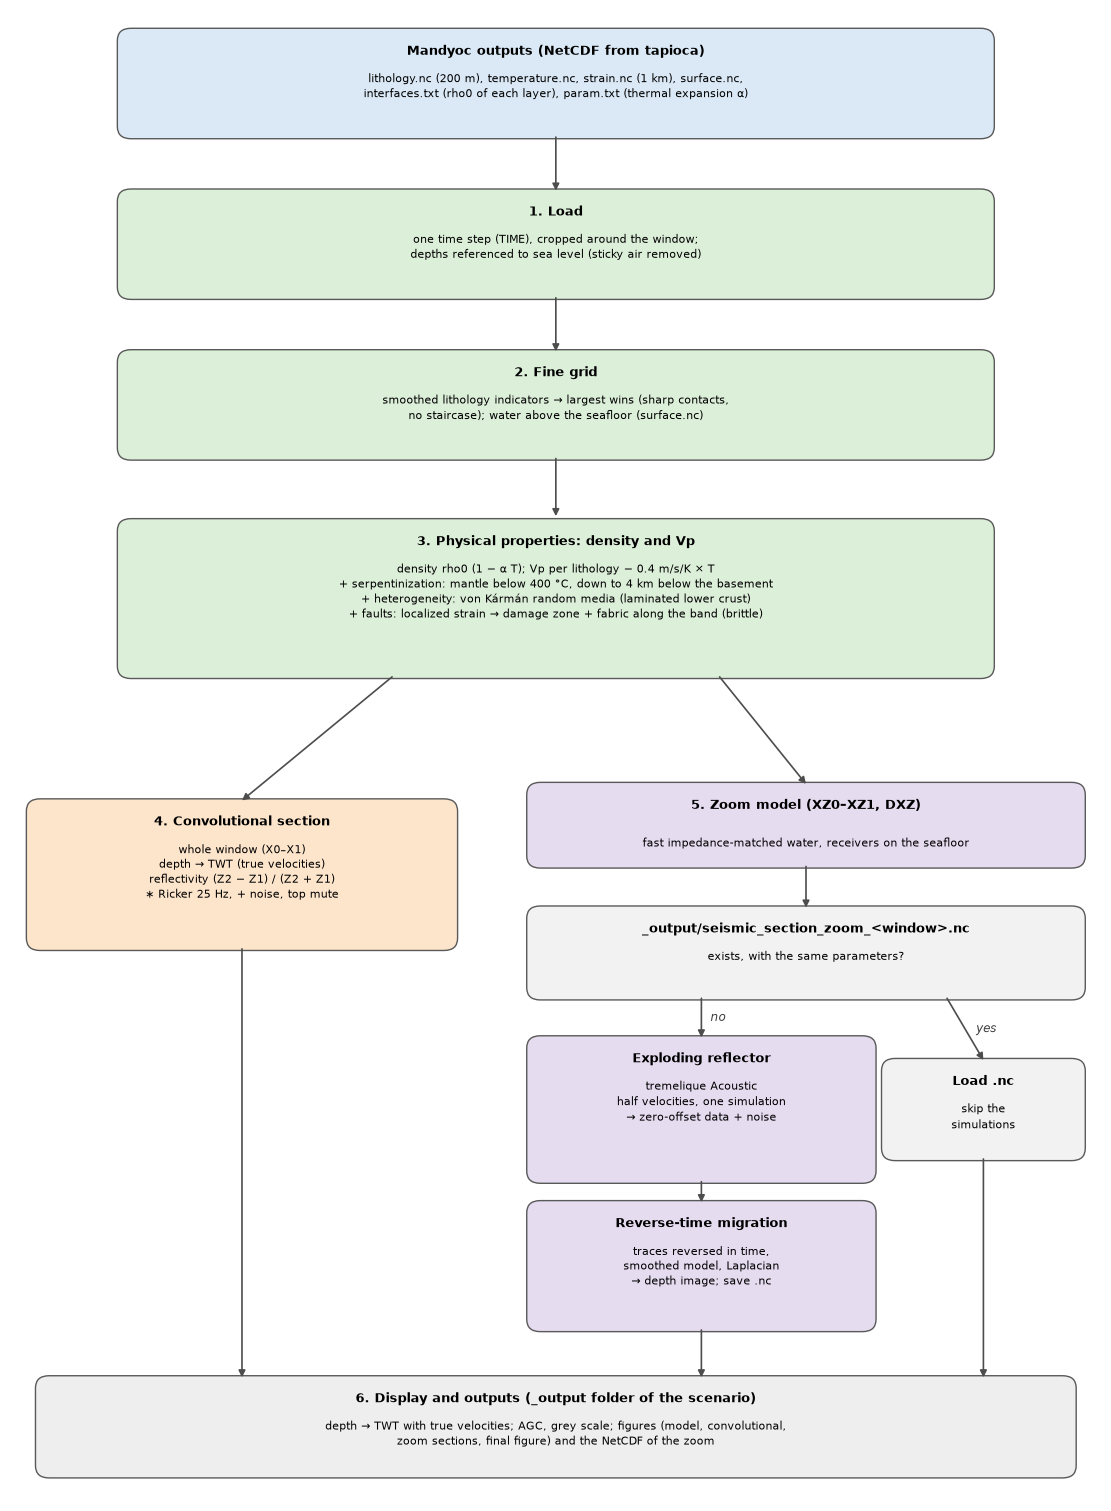

In [2]:
plot_flowchart(parallel=False)

## How to read this notebook

Real seismic sections of rifted margins are the result of three things: the
geology, the physics of wave propagation, and the processing. Mandyoc gives
us the geology at a scale of hundreds of metres to kilometres (lithology,
temperature, strain); the seismic image depends on structure at the scale
of tens of metres (the wavelength). Most of the choices below bridge that
gap in a physically motivated way, and are listed with their reason so that
they can be changed consciously. Each section explains **what** is done and
**why**.

## Parameters

All the choices are collected here. The main ones:

* **Model time (`TIME`)**: 25 Myr, after breakup, when the left margin is
  complete (necking, hyperextended crust, exhumed mantle), as in the
  Australia–Antarctica and Iberia–Newfoundland sections of Gillard et al.
* **Grid spacing (`DX` = 25 m)** for the convolutional section: a 25 Hz
  wavelet has wavelengths of ~250 m in the crust, so 25 m samples each
  wavelength ~10 times and keeps the thin laminations of the heterogeneity.
* **Zoom grid (`DXZ` = 20 m)** for tremelique: the finite-difference cost
  grows with the 3rd power of 1/dx (2 spatial dimensions + time step), so
  20 m is a compromise between frequency and run time (see section 5).
* **Vp per lithology**: typical values for continental crust and mantle
  (e.g. Christensen & Mooney, 1995), corrected by temperature with
  `DVPDT` = −0.4 m/s/K, a typical laboratory value for crustal and mantle
  rocks.

In [3]:
DATA = Path("/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc40_Cmlit025_Ts0_1080")  # Mandyoc outputs
TIME = 25.0  # model time [Myr] (nearest output is used)
SEED = 42

# Whole window (convolutional section)
X0, X1 = 740e3, 1000e3  # [m]
ZMAX = 40e3  # maximum depth below sea level [m]
DX = 25.0  # grid spacing [m]
SMOOTH = 300.0  # std of the Gaussian that smooths interface geometry [m]

ALPHA = 3.28e-5  # thermal expansion coefficient (param.txt) [1/K]
DVPDT = -0.4  # temperature derivative of Vp [m/s/K]
RHO_WATER, VP_WATER = 1030.0, 1500.0

# Lithology codes follow the column order of interfaces.txt
LITHOLOGIES = {
    0: dict(name="asthenosphere", vp0=8450.0),
    1: dict(name="lithospheric mantle", vp0=8450.0),
    2: dict(name="lithospheric mantle (weak)", vp0=8450.0),
    3: dict(name="lithospheric mantle", vp0=8450.0),
    4: dict(name="lower crust", vp0=7000.0),
    5: dict(name="upper crust", vp0=6250.0),
}
MANTLE = [0, 1, 2, 3]
WATER = 7  # code given to the water layer

# Serpentinization: mantle colder than SERP_TMAX, decreasing linearly from
# fully serpentinized at the top of the basement to zero at SERP_DEPTH below it
SERP_DEPTH = 4000.0  # [m]
SERP_TMAX = 400.0  # [°C]
VP_SERP, RHO_SERP = 4300.0, 2550.0

# Heterogeneity: std of the relative Vp perturbation and correlation lengths
# along (ax) and across (az) the fabric [m]. It only perturbs velocities
# inside each layer: the geometry (thinning, exhumation) is unchanged.
# Density follows with d(ln rho) = RHO_VP * d(ln Vp).
HETEROGENEITY = [
    dict(codes=[5], std=0.03, ax=1500.0, az=400.0),  # upper crust
    dict(codes=[4], std=0.05, ax=4000.0, az=150.0),  # lower crust (laminated)
    dict(codes=MANTLE, std=0.015, ax=1000.0, az=1000.0),  # mantle
]
SERP_HETEROGENEITY = dict(std=0.06, ax=400.0, az=400.0)
RHO_VP = 0.25
HURST = 0.3

# Faults from strain: shear bands = strain minus its regional mean (Gaussian
# of std HIGHPASS), normalised; brittle where T < BRITTLE_T[0], fading out
# at BRITTLE_T[1]
FAULTS = dict(highpass=4000.0, damage=0.05, std=0.07, ax=3000.0, az=100.0,
              dip_step=15.0)  # fmt: skip
BRITTLE_T = (550.0, 700.0)  # [°C]

# Convolutional section
CONV_DT = 0.002  # [s]
CONV_FPEAK = 25.0  # Ricker peak frequency [Hz]
NOISE = 0.05  # random noise, relative to the RMS of the section
AGC_WINDOW = 0.25  # [s]
# Candidate zoom windows (x start, x end, TWT start) [m, m, s], 4 s long
CANDIDATES = [(800e3, 870e3, 3.0), (850e3, 920e3, 5.0), (900e3, 980e3, 6.3)]

# Zoom (finite differences)
XZ0, XZ1 = 750e3, 900e3  # [m]
ZOOM_T0, ZOOM_TLEN = 0.0, 10.0  # TWT window of the zoom display [s]
ZOOM_TAG = f"{XZ0 / 1e3:.0f}-{XZ1 / 1e3:.0f}km"  # in the names of the saved figures
ZZMAX = 36e3  # [m]
DXZ = 20.0  # [m]
PAD = 60  # absorbing padding [cells]

## 1. Load Mandyoc outputs

Only the time step `TIME` is read, cropped around the window, to keep memory
low (the lithology has 200 m resolution over 1600 × 400 km).

**Depth reference.** Mandyoc's z axis starts at the top of the box, which
includes a layer of sticky air. Seismic sections are referenced to sea
level, so depths are shifted by the sticky-air thickness (`AIR`), taken as
the mean of the initial surface, which is where Mandyoc's `sea_level = 0`
lies. The seafloor comes from `surface.nc` (25 m sampling), which is much
smoother than the boundary of the air in the lithology grid.

In [4]:
def load(name):
    """One time step of a Mandyoc field, cropped around the window."""
    da = xr.open_dataset(DATA / f"{name}.nc")[name].sel(time=TIME, method="nearest")
    return da.sel(x=slice(X0 - 20e3, X1 + 20e3),
                  z=slice(-(AIR + ZMAX + 20e3), None)).load()  # fmt: skip


surf_all = xr.open_dataset(DATA / "surface.nc").surface
# Sea level: mean of the initial surface (Mandyoc sea_level = 0 is relative to it)
AIR = -float(surf_all.isel(time=0).mean())
surf = surf_all.sel(time=TIME, method="nearest").load()
lith, temp, strain = load("lithology"), load("temperature"), load("strain")
print(f"time = {float(lith.time):.2f} Myr, sticky air = {AIR / 1e3:.0f} km")

with open(DATA / "interfaces.txt") as f:
    for line in f:
        if line.startswith("rho"):
            RHO0 = np.array(line.split()[1:], dtype=float)

# Figures are saved in the _output folder of the scenario
OUTPUT = DATA / "_output"
OUTPUT.mkdir(exist_ok=True)


def save(fig, name):
    fig.savefig(OUTPUT / f"seismic_section_{name}.png", dpi=200)

time = 25.18 Myr, sticky air = 40 km


## Lithology display (colours of the videos)

The lithology plots use the colours of the Mandyoc videos
(`functions/mandyocIO.py`), so the figures can be compared with them
directly. Serpentinized mantle (degree ≥ 0.5) is a darker green, and the
faults are shaded in purple on top of the lithology, with an opacity
proportional to the fault weight (the same field shown in the "Faults"
panel), instead of contour lines, which would draw closed polygons around
shear bands.

In [5]:
LITHO_COLORS = get_lithology_colors(str(DATA), "auto")  # one colour per Mandyoc code
UNITS = [  # (label, colour) of each display unit
    ("water", COLOR_WATER),
    ("upper crust", LITHO_COLORS[5]),
    ("lower crust", LITHO_COLORS[4]),
    ("lithospheric mantle", LITHO_COLORS[1]),
    ("asthenosphere", LITHO_COLORS[0]),
    ("serpentinized mantle", (95 / 255, 150 / 255, 105 / 255)),  # darker green
]
UNITS_CMAP = plt.matplotlib.colors.ListedColormap([c for _, c in UNITS])
UNITS_CMAP.set_under("white")  # below the bottom of the model
FAULTS_CMAP = plt.get_cmap("Purples")


def lithology_units(m):
    """Display unit (index of UNITS) of every cell of a model."""
    return np.select(
        [~m["rock"], m["serp"] >= 0.5, m["litho"] == 5, m["litho"] == 4, m["litho"] == 0],
        [0, 5, 1, 2, 4],
        default=3,
    ).astype(np.int8)


def plot_units(ax, units, faults, extent):
    """Lithology in the colours of the videos, with the faults shaded on top."""
    ax.imshow(units, extent=extent, aspect="auto", cmap=UNITS_CMAP, vmin=-0.5,
              vmax=len(UNITS) - 0.5, interpolation="nearest")  # fmt: skip
    faults = np.nan_to_num(np.clip(faults, 0, 1))
    ax.imshow(faults, extent=extent, aspect="auto", cmap=FAULTS_CMAP, vmin=0, vmax=1,
              alpha=0.9 * faults, interpolation="nearest")  # fmt: skip
    handles = [plt.matplotlib.patches.Patch(color=c, label=n) for n, c in UNITS]
    handles.append(plt.matplotlib.patches.Patch(color=FAULTS_CMAP(0.8),
                                                label="faults (localized strain)"))  # fmt: skip
    ax.legend(handles=handles, loc="lower right", fontsize=8, ncol=2)
    ax.set_title("Lithology")

## 2–3. Model builder

`build_model` turns the Mandyoc fields into density and P-wave velocity on
a fine grid. Each step, and why:

1. **Lithology on the fine grid.** Each lithology is turned into an
   indicator (1 inside, 0 outside), interpolated, smoothed with a Gaussian
   (`SMOOTH` = 300 m) and the lithology with the largest value wins. This
   keeps contacts **sharp** (a sharp impedance contrast is what makes a
   reflection) but removes the staircase of the Mandyoc grid and the noise
   of the particles, which would otherwise create spurious diffractions.
2. **Water** fills everything above the seafloor. There are no sediments:
   the scenario has no surface processes, and the aim here is the basement.
3. **Density** `rho0 (1 − α T)`, with `rho0` from `interfaces.txt` and α
   from `param.txt`, i.e. the same thermal expansion used by Mandyoc.
   `density.nc` is not used directly because it is on the 1 km mesh and
   smears contacts.
4. **Vp** per lithology with a temperature correction: hot mantle under the
   rift is slower than cold mantle, as observed in refraction data.
5. **Serpentinization.** At magma-poor margins the exhumed mantle is
   hydrated near its top; Gillard et al. (2019) summarise refraction
   velocities increasing from ~4.3 km/s at the top of the basement to
   ~7.3 km/s a few km below it. Serpentinization needs water (so it
   decreases with depth below the top of the basement, reaching zero at
   `SERP_DEPTH` = 4 km) and low temperature (serpentine is not formed
   above ~400 °C, `SERP_TMAX`). The serpentinized fraction mixes the
   velocity and density of the mantle with those of serpentinite.
6. **Small-scale heterogeneity.** Real basement is not homogeneous, and
   its internal reflectivity gives seismic sections their texture. It is
   represented with von Kármán random media, the standard description of
   crustal heterogeneity in seismic scattering studies (e.g. Frankel &
   Clayton, 1986). The perturbations are a few percent and **only change
   velocities inside each layer, never the geometry**. Lower continental
   crust is often laminated and reflective, so its perturbations are long
   horizontally (4 km) and thin vertically (150 m); the upper crust is
   weaker and more isotropic; the mantle is nearly transparent; the
   serpentinized mantle is the most heterogeneous.
7. **Faults from the strain.** The 1 km strain field resolves the shear
   bands (faults, detachments, conjugate systems). The regional trend of the
   strain is removed (Gaussian high-pass, `highpass` = 4 km) so that only
   *localized* strain remains. Where strain is localized:
   * a **damage zone** lowers Vp by up to 5% (fault rocks are slower);
   * a **fabric laminated along the band** is added, with its orientation
     taken from the structure tensor of the strain field, so that fault
     zones reflect like the sheared, layered rocks they represent.

   Faults are only kept in the brittle domain (T < 550–700 °C), where
   discrete faults are expected; deeper, hot strain is distributed flow.

In [6]:
def von_karman(shape, spacing, ax, az, dip=0.0, rng=None):
    """Unit-variance von Kármán random field, elongated along ``dip``."""
    nz, nx = shape
    kz = 2 * np.pi * scipy.fft.fftfreq(nz, spacing)[:, None]
    kx = 2 * np.pi * scipy.fft.rfftfreq(nx, spacing)[None, :]
    theta = np.deg2rad(dip)  # positive: deepens towards +x
    k_along = kx * np.cos(theta) + kz * np.sin(theta)
    k_across = -kx * np.sin(theta) + kz * np.cos(theta)
    amplitude = (1 + (k_along * ax) ** 2 + (k_across * az) ** 2) ** (-(HURST + 1) / 2)
    noise = rng.standard_normal(shape, dtype=np.float32)
    spectrum = scipy.fft.rfft2(noise, workers=-1) * amplitude.astype(np.float32)
    field = scipy.fft.irfft2(spectrum, s=shape, workers=-1)
    return (field / field.std()).astype(np.float32)


def band_dip(field, spacing, sigma=1000.0, window=2000.0):
    """Dip [deg] of the bands of ``field`` from its structure tensor."""
    smooth = gaussian_filter(field, sigma / spacing)
    gz, gx = np.gradient(smooth)
    jxx = gaussian_filter(gx * gx, window / spacing)
    jxz = gaussian_filter(gx * gz, window / spacing)
    jzz = gaussian_filter(gz * gz, window / spacing)
    normal = 0.5 * np.arctan2(2 * jxz, jxx - jzz)  # direction of the gradient
    dip = np.rad2deg(normal) + 90.0  # bands are perpendicular to it
    return ((dip + 90.0) % 180.0 - 90.0).astype(np.float32)  # in [-90, 90)


def build_model(x, depth, seed=SEED):
    """Lithology, temperature, density and Vp on the (depth, x) grid."""
    spacing = x[1] - x[0]
    xx, dd = np.meshgrid(x.astype(np.float32), depth.astype(np.float32))
    points = np.column_stack([dd.ravel(), xx.ravel()])

    def to_fine(da):
        d = -da.z.values - AIR  # depth below sea level, positive down
        order = np.argsort(d)
        values = np.asarray(da.values, dtype=float)[order]
        interp = RegularGridInterpolator((d[order], da.x.values), values,
                                         bounds_error=False, fill_value=None)  # fmt: skip
        return interp(points).reshape(dd.shape).astype(np.float32)

    # Smooth each lithology indicator and take the argmax: sharp contacts with
    # smooth geometry
    best = np.full(dd.shape, -np.inf, dtype=np.float32)
    litho = np.zeros(dd.shape, dtype=np.int8)
    for c in sorted(LITHOLOGIES):
        indicator = to_fine((lith == c).astype(float))
        indicator = gaussian_filter(indicator, SMOOTH / spacing, mode="nearest")
        litho[indicator > best] = c
        best = np.maximum(best, indicator)
    del best

    seafloor = np.clip(-surf.interp(x=x).values - AIR, 0, None)  # top of basement
    litho[dd < seafloor[None, :]] = WATER
    rock = litho != WATER
    temperature = np.clip(to_fine(temp), 0, None)
    temperature[~rock] = 0.0
    accumulated_strain = to_fine(strain)

    rho0 = np.array([RHO0[c] for c in sorted(LITHOLOGIES)], dtype=np.float32)
    vp0 = np.array([LITHOLOGIES[c]["vp0"] for c in sorted(LITHOLOGIES)], dtype=np.float32)
    density = np.full(dd.shape, RHO_WATER, dtype=np.float32)
    vp = np.full(dd.shape, VP_WATER, dtype=np.float32)
    density[rock] = rho0[litho[rock]] * (1 - ALPHA * temperature[rock])
    vp[rock] = vp0[litho[rock]] + DVPDT * temperature[rock]

    # Serpentinization of the cold, shallow mantle
    below_basement = dd - seafloor[None, :].astype(np.float32)
    serp = (
        np.isin(litho, MANTLE)
        * np.clip(1 - below_basement / SERP_DEPTH, 0, 1)
        * np.clip((SERP_TMAX - temperature) / 50.0, 0, 1)
    ).astype(np.float32)
    vp = (1 - serp) * vp + serp * VP_SERP
    density = (1 - serp) * density + serp * RHO_SERP

    # Heterogeneity (relative Vp perturbation)
    rng = np.random.default_rng(seed)
    dlnv = np.zeros(dd.shape, dtype=np.float32)
    for het in HETEROGENEITY:
        field = von_karman(dd.shape, spacing, het["ax"], het["az"], rng=rng)
        dlnv += np.isin(litho, het["codes"]) * (1 - serp) * het["std"] * field
    h = SERP_HETEROGENEITY
    dlnv += serp * h["std"] * von_karman(dd.shape, spacing, h["ax"], h["az"], rng=rng)

    # Faults: localized strain -> damage zone + fabric along the shear band
    bands = np.clip(accumulated_strain - gaussian_filter(
        accumulated_strain, FAULTS["highpass"] / spacing, mode="nearest"), 0, None)  # fmt: skip
    bands /= np.percentile(bands[rock], 99)
    brittle = np.clip((BRITTLE_T[1] - temperature) / (BRITTLE_T[1] - BRITTLE_T[0]), 0, 1)
    faults = (rock * brittle * np.clip(bands, 0, 1)).astype(np.float32)
    dlnv -= FAULTS["damage"] * faults
    dip = band_dip(accumulated_strain, spacing)
    step = FAULTS["dip_step"]
    for d in np.arange(-90.0, 90.0, step):
        delta = np.abs((dip - d + 90.0) % 180.0 - 90.0)  # angular distance
        weight = faults * np.clip(1 - delta / step, 0, 1)
        if weight.max() > 0:
            field = von_karman(dd.shape, spacing, FAULTS["ax"], FAULTS["az"], dip=d,
                               rng=rng)  # fmt: skip
            dlnv += weight * FAULTS["std"] * field
    vp[rock] *= 1 + dlnv[rock]
    density[rock] *= 1 + RHO_VP * dlnv[rock]

    return dict(x=x, depth=depth, litho=litho, seafloor=seafloor, rock=rock,
                temperature=temperature, strain=accumulated_strain, serp=serp,
                faults=faults, density=density, vp=vp)  # fmt: skip


def two_way_time(model):
    """TWT of every depth sample (vertical incidence).

    The water time uses the exact seafloor depth, so the staircase of the grid
    does not shift whole columns.
    """
    dz = model["depth"][1] - model["depth"][0]
    vp, rock = model["vp"], model["rock"]
    rock_time = 2 * np.cumsum(np.where(rock, dz / vp, 0), axis=0) - 2 * dz / vp
    water_time = 2 * model["depth"][:, None] / VP_WATER
    return np.where(rock, 2 * model["seafloor"][None, :] / VP_WATER + rock_time,
                    water_time)  # fmt: skip


def reflectivity(model):
    impedance = model["density"] * model["vp"]
    r = np.zeros_like(impedance)
    r[1:] = (impedance[1:] - impedance[:-1]) / (impedance[1:] + impedance[:-1])
    return r

serpentinized area: 163 km² (equivalent)


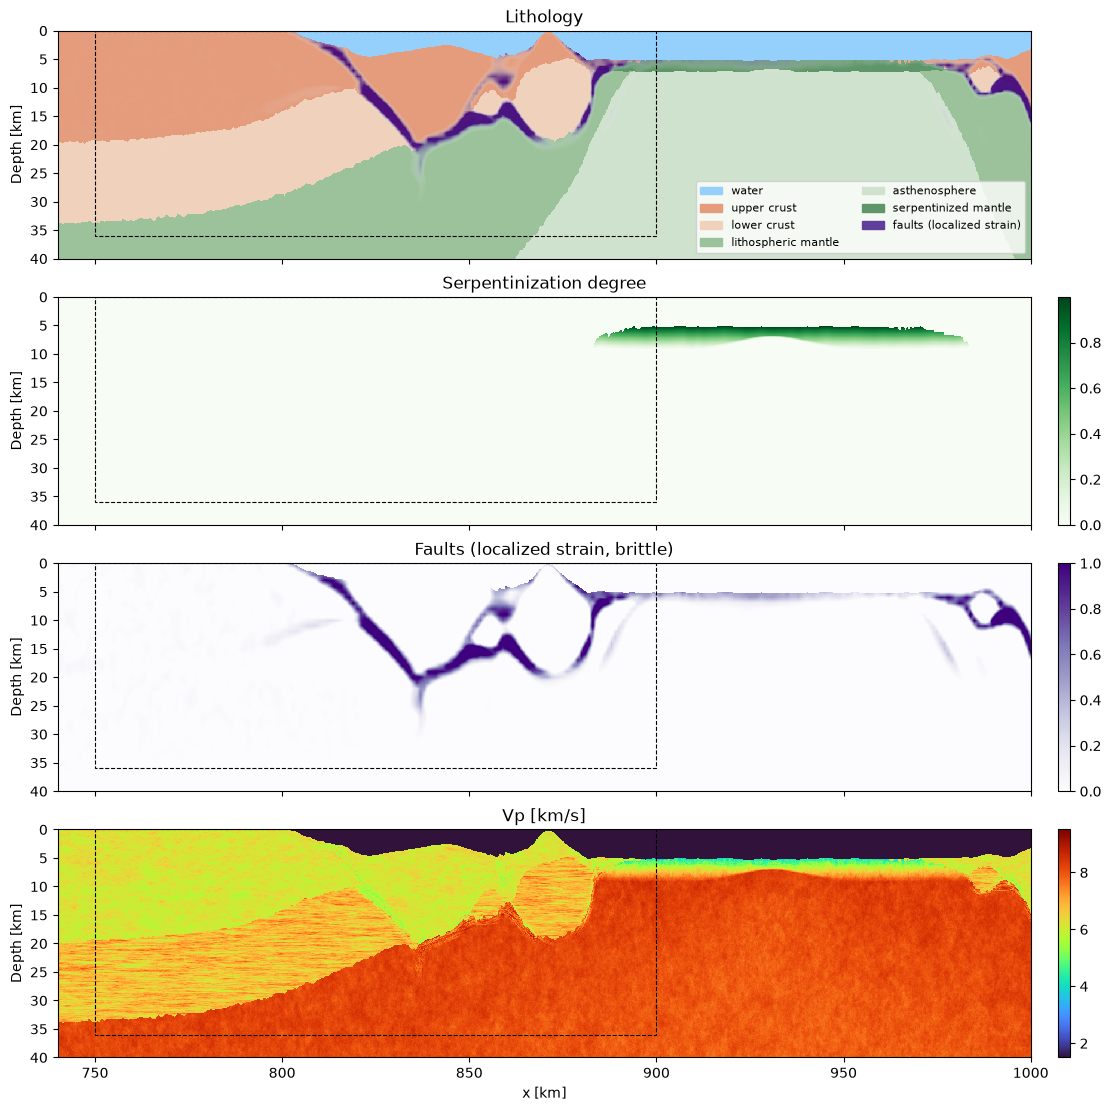

In [7]:
model = build_model(np.arange(X0, X1 + DX / 2, DX), np.arange(0, ZMAX + DX / 2, DX))
x, depth = model["x"], model["depth"]
extent = [X0 / 1e3, X1 / 1e3, ZMAX / 1e3, 0]
print(f"serpentinized area: {model['serp'].sum() * DX**2 / 1e6:.0f} km² (equivalent)")

fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True, layout="constrained")
plot_units(axes[0], lithology_units(model)[::4, ::4], model["faults"][::4, ::4], extent)
for ax, field, title, cmap in zip(
    axes[1:],
    [model["serp"], model["faults"], model["vp"] / 1e3],
    ["Serpentinization degree", "Faults (localized strain, brittle)", "Vp [km/s]"],
    ["Greens", "Purples", "turbo"],
):  # fmt: skip
    im = ax.imshow(field[::4, ::4], extent=extent, aspect="auto", cmap=cmap,
                   interpolation="none")  # fmt: skip
    ax.set_title(title)
    fig.colorbar(im, ax=ax, pad=0.01)
for ax in axes:
    ax.add_patch(plt.Rectangle((XZ0 / 1e3, 0), (XZ1 - XZ0) / 1e3, ZZMAX / 1e3,
                               fill=False, ec="k", ls="--", lw=0.8))  # fmt: skip
    ax.set_ylabel("Depth [km]")
axes[-1].set_xlabel("x [km]")
save(fig, "model")

## Display helpers

The sections are displayed like processed field data:

* **Ricker wavelet**: zero-phase, the usual choice for synthetic seismograms.
* **Random noise** (5% of the RMS), band-limited by the wavelet: real data
  always have noise, and without it the AGC would amplify numerical
  zeros into artificially clean images.
* **AGC** (automatic gain control, 0.25 s window): balances the strong
  seafloor reflection and the weak deep reflections, as done in the
  published sections. A short window keeps the texture right below the
  seafloor visible.
* **Grey scale**, clipped at the 98th percentile, as in the papers.

In [8]:
def ricker(time, fpeak):
    a = (np.pi * fpeak * time) ** 2
    return (1 - 2 * a) * np.exp(-a)


def agc(section, window, dt):
    """Automatic gain control with a sliding RMS window [s]."""
    n = max(int(window / dt), 1)
    section = np.asarray(section, dtype=float)
    rms = np.sqrt(np.maximum(uniform_filter1d(section**2, n, axis=0), 0))
    return section / (rms + 1e-3 * rms.max())


def add_noise(section, level, wavelet, rng):
    """Band-limited random noise with RMS = level * RMS(section)."""
    noise = rng.standard_normal(section.shape, dtype=np.float32)
    noise = oaconvolve(noise, wavelet[:, None].astype(np.float32), mode="same", axes=0)
    rms = np.sqrt(np.mean(section.astype(float) ** 2))
    return section + (level * rms / noise.std() * noise).astype(np.float32)


def plot_seismic(section, time, xs, ax, title, tlim=None, clip=98, gain=AGC_WINDOW):
    """Grey-scale variable-density display in TWT, in the style of the papers."""
    if tlim is not None:  # crop first: faster and the clip uses only what is shown
        keep = (time >= tlim[0]) & (time <= tlim[1])
        section, time = section[keep], time[keep]
    data = agc(section, gain, time[1] - time[0]) if gain else section
    vmax = np.percentile(np.abs(data), clip)
    ax.imshow(data, extent=[xs[0] / 1e3, xs[-1] / 1e3, time[-1], time[0]],
              aspect="auto", cmap="gray_r", vmin=-vmax, vmax=vmax,
              interpolation="antialiased")  # fmt: skip
    ax.set_title(title)
    ax.set_ylabel("TWT [s]")
    ax.set_xlabel("x [km]")


def depth_to_time(image, twt, time):
    """Resample each column of a depth image onto a TWT axis."""
    return np.stack([np.interp(time, twt[:, j], image[:, j], left=0, right=0)
                     for j in range(image.shape[1])], axis=1)  # fmt: skip

## 4. Convolutional section (whole window)

Each column is converted from depth to two-way time (TWT) with the true
velocities, and its normal-incidence reflectivity
`(Z2 − Z1) / (Z2 + Z1)`, with impedance `Z = rho Vp`, is convolved with a
Ricker wavelet.

**Why:** it is cheap (seconds for the whole 260 km window) and can use a
realistic frequency (25 Hz), so it shows what the model "looks like" in
seismic at the scale of the papers, and helps choose where to zoom.

**Limits:** each trace is 1D, as if the section were perfectly migrated
and every reflector were horizontal. There are no diffractions, no
focusing, and steeply dipping reflectors are shown with full amplitude,
whereas real acquisition and migration would image them poorly. The water
TWT uses the exact seafloor depth, so the 25 m grid steps do not shift the
traces. The water column is muted, as in processed data.

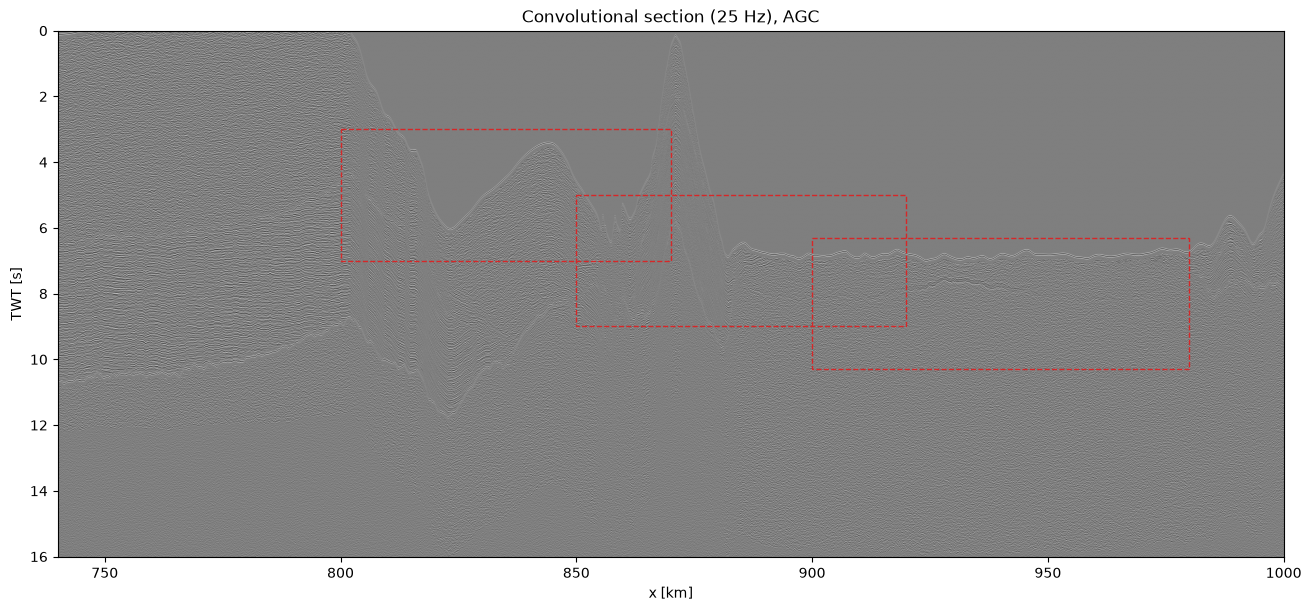

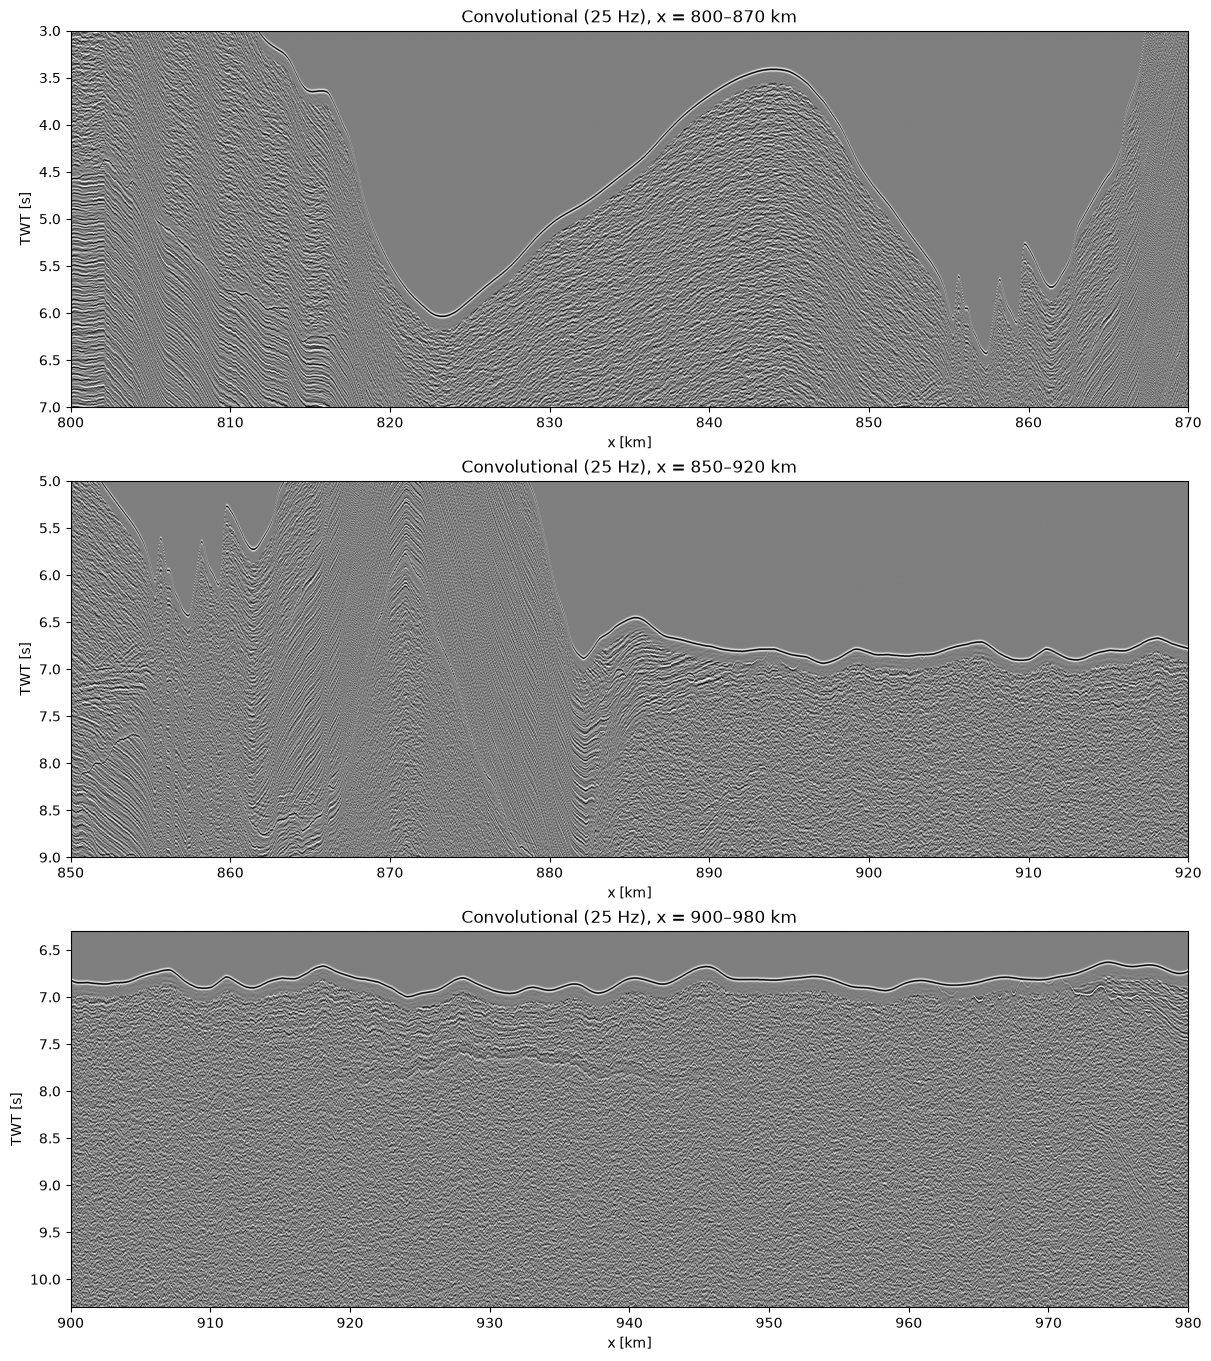

In [9]:
twt = two_way_time(model)
t = np.arange(0, twt.max() + CONV_DT, CONV_DT)
spikes = np.zeros((t.size, x.size), dtype=np.float32)
cols = np.broadcast_to(np.arange(x.size), twt.shape)
np.add.at(spikes, (np.round(twt / CONV_DT).astype(int), cols), reflectivity(model))
wavelet = ricker(np.arange(-0.1, 0.1 + CONV_DT / 2, CONV_DT), CONV_FPEAK)
conv = oaconvolve(spikes, wavelet[:, None].astype(np.float32), mode="same", axes=0)
conv = add_noise(conv, NOISE, wavelet, np.random.default_rng(SEED + 1))
del spikes
seafloor_twt = 2 * model["seafloor"] / VP_WATER
conv[t[:, None] < seafloor_twt[None, :] - 0.05] = 0  # top mute (water column)

fig, ax = plt.subplots(figsize=(13, 6), layout="constrained")
plot_seismic(conv, t, x, ax, f"Convolutional section ({CONV_FPEAK:.0f} Hz), AGC",
             tlim=(seafloor_twt.min() - 0.3, t[-1]))  # fmt: skip
for xa, xb, ta in CANDIDATES:
    ax.add_patch(plt.Rectangle((xa / 1e3, ta), (xb - xa) / 1e3, 4.0, fill=False,
                               ec="tab:red", ls="--", lw=1))  # fmt: skip
save(fig, "convolutional")

# Zooms at the scale of the published sections (4 s TWT windows)
fig, axes = plt.subplots(len(CANDIDATES), 1, figsize=(12, 4.5 * len(CANDIDATES)),
                         layout="constrained")  # fmt: skip
for ax, (xa, xb, ta) in zip(np.atleast_1d(axes), CANDIDATES):
    keep = (x >= xa) & (x <= xb)
    plot_seismic(conv[:, keep], t, x[keep], ax,
                 f"Convolutional ({CONV_FPEAK:.0f} Hz), x = {xa / 1e3:.0f}–{xb / 1e3:.0f} km",
                 tlim=(ta, ta + 4.0))  # fmt: skip
save(fig, "convolutional_windows")

## 5. Zoom with tremelique: exploding reflector + RTM

Here the waves are actually propagated in 2D, with tremelique's
finite-difference acoustic solver, so diffractions, focusing and the
limited imaging of steep dips appear naturally. This is expensive, hence a
zoom.

**Why acoustic:** tremelique only has P waves for now. For marine
reflection seismic this is a good approximation, since streamer data are
dominated by P waves; converted S waves are not modelled.

**Why the exploding reflector (zero offset):** a real survey has hundreds
of shots and needs stacking and migration. The exploding reflector
(Loewenthal et al., 1976) gets the zero-offset section from **a single
simulation**: all reflectors fire at t = 0 with their reflection
coefficients, and the waves travel at half the velocity, so one-way time
equals two-way time. Its limits: multiples and amplitude versus offset are
not correct.

**Frequency and grid.** Finite differences need a minimum number of grid
points per wavelength (here ~4 at the highest frequency, `F_CUT`); with
fewer the waves become dispersive. The slowest medium sets the wavelength,
and the water, at half velocity, would be only 750 m/s.

* **Receivers on the seafloor (OBS).** The water column is only needed to
  carry the waves up to the sea surface, so it is replaced by a medium with
  the same impedance (same seafloor reflection coefficient) but a higher
  velocity, and absorbed above the receivers. This takes the slow water
  (750 m/s at half velocity) out of the dispersion budget and allows ~3x
  higher frequencies. The water TWT is added back in the time conversion.
* **Recording length**: long enough to fill the displayed TWT window below
  the shallowest receiver.
* **Boundaries**: tremelique damps the waves in a padding zone on the
  left, right and bottom (`PAD` cells), so the model edges do not reflect.

`Acoustic` is subclassed only to inject distributed or receiver sources in
a vectorised way, absorb the water layer, and keep traces in memory instead
of caching every panel to HDF5. The finite-difference kernel and boundary
conditions are tremelique's own.

In [10]:
@numba.jit(nopython=True)
def multiply_inplace(a, b):
    for i in range(a.shape[0]):
        for j in range(a.shape[1]):
            a[i, j] *= b[i, j]


class ZeroOffset(tr.Acoustic):
    def __init__(self, velocity, density, spacing, receivers, absorb, f_cut, **kw):
        super().__init__(velocity, density, spacing, cachefile="unused.h5", **kw)
        self.rec_z, self.rec_x = receivers
        self.absorb = absorb.astype(np.float32)
        self.wavelet = tr.RickerWavelet(1.0, f_cut)
        self.source_scale = None  # exploding reflector: 2D field x wavelet
        self.injection = None  # RTM: traces injected at the receivers
        self.traces = []
        self.last = None

    def _init_cache(self, npanels, **kwargs):
        pass

    def _expand_cache(self, npanels):
        pass

    def _cache_panels(self, u, tp1, iteration, simul_size):
        self.traces.append(u[tp1, self.rec_z, self.rec_x])
        self.last = u[tp1]

    def _timestep(self, u, tm1, t, tp1, iteration):
        nz, nx = self.shape
        timestep_esg(
            u[tp1], u[t], u[tm1], 3, nx - 3, 3, nz - 3,
            self.dt, self.dx, self.dz, self.velocity, self.density,
        )  # fmt: skip
        apply_damping(u[t], nx, nz, self.padding, self.taper)
        nonreflexive_bc(
            u[tp1], u[t], nx, nz, self.dt, self.dx, self.dz, self.velocity, self.density
        )
        apply_damping(u[tp1], nx, nz, self.padding, self.taper)
        multiply_inplace(u[t], self.absorb)
        multiply_inplace(u[tp1], self.absorb)
        if self.source_scale is not None:
            u[tp1] += self.source_scale * self.wavelet(iteration * self.dt)
        if self.injection is not None and iteration < len(self.injection):
            u[tp1, self.rec_z, self.rec_x] += self.injection[iteration]


def pad(a, mode="edge"):
    return np.pad(a, ((0, PAD), (PAD, PAD)), mode=mode)


zoom = build_model(np.arange(XZ0, XZ1 + DXZ / 2, DXZ), np.arange(0, ZZMAX + DXZ / 2, DXZ))
xz = zoom["x"]
water = ~zoom["rock"]
# Impedance-matched fast water; the slowest rock sets the frequency budget
# (~4 cells per wavelength at F_CUT, as before)
slow_rock = np.percentile(zoom["vp"][zoom["rock"]], 1)
vp_fd = np.where(water, slow_rock, zoom["vp"])
rho_fd = np.where(water, RHO_WATER * VP_WATER / slow_rock, zoom["density"])
F_CUT = slow_rock / 2 / (4 * DXZ)

rec_row = np.clip(np.round(zoom["seafloor"] / DXZ).astype(int) - 2, 3, None)
receivers = (rec_row, np.arange(PAD, PAD + xz.size))
# Absorb everything more than 5 cells above the receivers
rows = np.arange(vp_fd.shape[0] + PAD)[:, None]
above = np.clip(np.pad(rec_row, PAD, mode="edge")[None, :] - 5 - rows, 0, None)
absorb = np.exp(-((0.005 * above) ** 2))

source = reflectivity(zoom)  # seafloor coefficient sits on the first rock cell
source[:3] = 0  # rows 0-2 are overwritten by the top boundary condition

delay = 2 * np.sqrt(np.pi) / F_CUT  # tremelique's causal Ricker delay
# Record long enough to fill the displayed window under the shallowest receiver
record = ZOOM_T0 + ZOOM_TLEN - two_way_time(zoom)[rec_row, np.arange(xz.size)].min()


def exploding_reflector():
    """Zero-offset data at the receivers (the slow part). Returns data, dt."""
    sim = ZeroOffset(pad(vp_fd / 2), pad(rho_fd), DXZ, receivers, absorb, F_CUT,
                     padding=PAD)  # fmt: skip
    sim.source_scale = (-sim.density * (sim.velocity * sim.dt) ** 2
                        * pad(source, "constant")).astype(np.float32)  # fmt: skip
    nsteps = int(np.ceil((record + delay) / sim.dt))
    print(f"zoom grid {sim.shape}, dt = {sim.dt * 1e3:.2f} ms, {nsteps} steps, "
          f"F_CUT = {F_CUT:.1f} Hz (peak {F_CUT / 3:.1f} Hz)")  # fmt: skip
    sim.run(nsteps)
    data = np.array(sim.traces)
    # Band-limited noise, as in real data, before migration
    fd_wavelet = sim.wavelet(np.arange(0, 2 * delay, sim.dt))
    data = add_noise(data, NOISE, fd_wavelet, np.random.default_rng(SEED + 2))
    return data, sim.dt

### Reverse-time migration

Real sections are migrated: diffractions collapse back to their points and
dipping reflectors move to their true positions. Reverse-time migration
(RTM; Baysal et al., 1983) is the natural choice here because it uses the
same wave-equation solver: the recorded traces, **reversed in time**, are
injected at the receivers and propagated back; the wave field at the time
of the source peak is the image. Choices:

* the migration model is **smoothed** (250 m): a sharp model would reflect
  the back-propagated waves and create artefacts;
* the image is filtered with a **Laplacian**, which removes the
  low-wavenumber noise typical of RTM;
* the data include the band-limited noise added above, so the migration
  also handles noise, as with field data.

In [11]:
def reverse_time_migration(data, dt):
    """Depth image from the zero-offset data (the other slow part)."""
    smooth_vp = gaussian_filter(pad(vp_fd / 2), 250 / DXZ).astype(np.float32)
    smooth_rho = gaussian_filter(pad(rho_fd), 250 / DXZ).astype(np.float32)
    rtm = ZeroOffset(smooth_vp, smooth_rho, DXZ, receivers, absorb, F_CUT, padding=PAD,
                     dt=dt)  # fmt: skip
    n_delay = int(round(delay / dt))
    scale = -smooth_rho[receivers] * (smooth_vp[receivers] * dt) ** 2
    rtm.injection = (data[::-1] * scale).astype(np.float32)  # step m <- trace N-1-m
    rtm.run(len(data) - n_delay)  # stop at the time of the source peak
    image = -gaussian_laplace(rtm.last[:-PAD, PAD:-PAD], 1.0)  # remove low wavenumbers
    image[water] = 0
    return image

### Run the simulations, or load them from the cache

The two tremelique runs above take most of the time of this notebook
(minutes to an hour, depending on the zoom): every time step updates every
cell of the grid, thousands of times, twice. Their results are saved in
`_output/seismic_section_zoom_<window>.nc` (NetCDF, readable with
`xarray.open_dataset`), together with the parameters that produced them.
When the notebook runs again with the **same parameters**, the file is
loaded instead; if any parameter changed, the simulations run again and
the file is overwritten. Set `RERUN = True` to force the simulations.

In [12]:
RERUN = False
ZOOM_FILE = OUTPUT / f"seismic_section_zoom_{ZOOM_TAG}.nc"
# Everything that changes the zoom results
PARAMETERS = json.dumps(dict(
    TIME=TIME, SEED=SEED, SMOOTH=SMOOTH, ALPHA=ALPHA, DVPDT=DVPDT,
    RHO_WATER=RHO_WATER, VP_WATER=VP_WATER, LITHOLOGIES=LITHOLOGIES,
    SERP_DEPTH=SERP_DEPTH, SERP_TMAX=SERP_TMAX, VP_SERP=VP_SERP, RHO_SERP=RHO_SERP,
    HETEROGENEITY=HETEROGENEITY, SERP_HETEROGENEITY=SERP_HETEROGENEITY,
    RHO_VP=RHO_VP, HURST=HURST, FAULTS=FAULTS, BRITTLE_T=BRITTLE_T, NOISE=NOISE,
    XZ0=XZ0, XZ1=XZ1, ZZMAX=ZZMAX, DXZ=DXZ, PAD=PAD, ZOOM_T0=ZOOM_T0,
    ZOOM_TLEN=ZOOM_TLEN,
), sort_keys=True)  # fmt: skip

cached = None
if ZOOM_FILE.exists() and not RERUN:
    cached = xr.load_dataset(ZOOM_FILE)
    if cached.attrs.get("parameters") != PARAMETERS:
        print(f"{ZOOM_FILE.name}: parameters changed, running the simulations again")
        cached = None
if cached is None:
    data, dt = exploding_reflector()
    image = reverse_time_migration(data, dt)
else:
    print(f"loaded {ZOOM_FILE}")
    image, dt = cached["image"].values, cached.attrs["dt"]

loaded /Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc40_Cmlit025_Ts0_1080/_output/seismic_section_zoom_750-900km.nc


### Zoom sections in TWT

The RTM image is in depth; it is converted to TWT with the **true**
velocities (including the real 1500 m/s water), so it can be compared with
the convolutional section and with published sections, which are shown in
TWT. The unmigrated section is shifted by the TWT of each receiver.

The lithology is converted to TWT in the same way. Because the TWT–depth
relation changes along x (water, crust and mantle have very different
velocities), the depth axis on the right is only approximate: it uses the
median relation over the zoom.

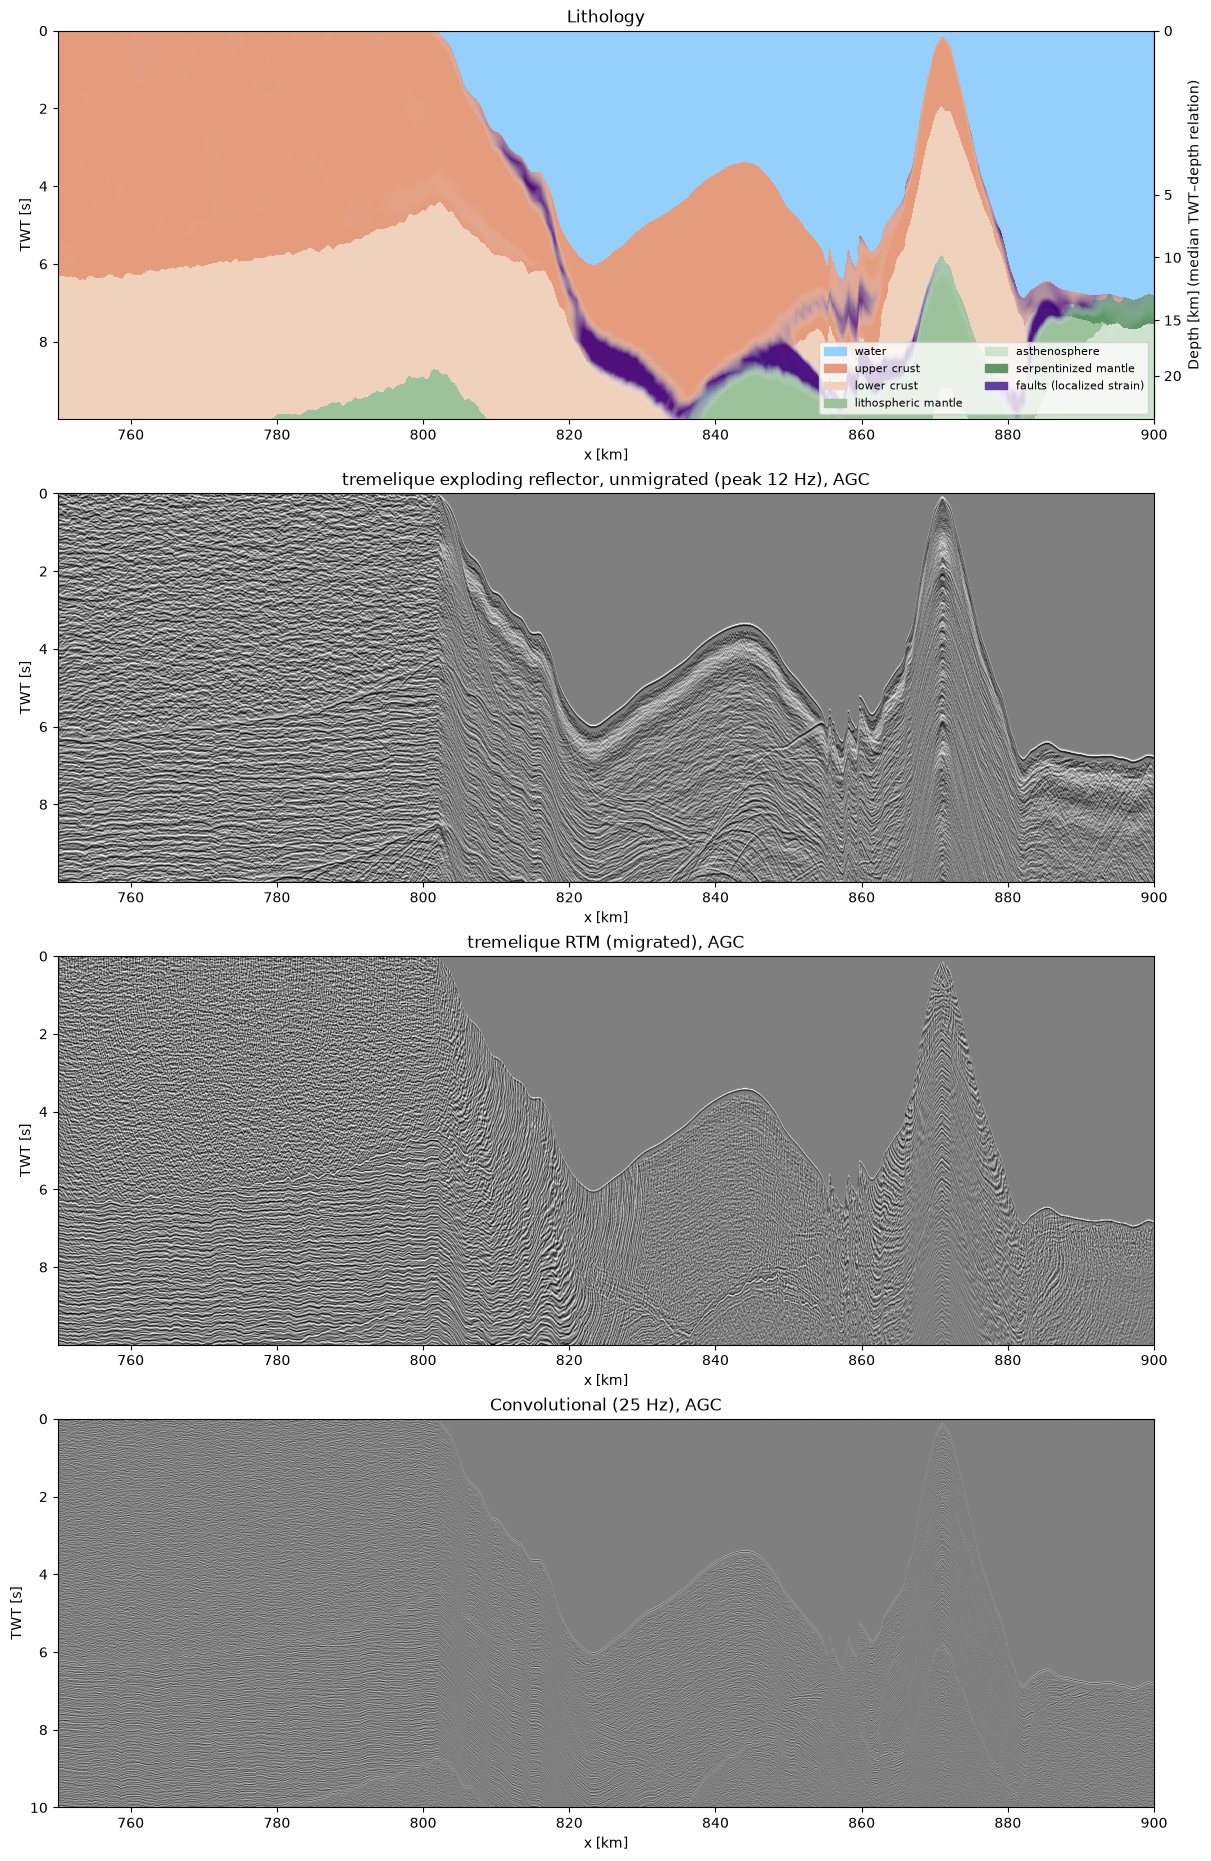

In [13]:
twt_zoom = two_way_time(zoom)
tz = np.arange(ZOOM_T0, ZOOM_T0 + ZOOM_TLEN + dt / 2, dt)  # displayed TWT window
in_zoom = (x >= XZ0) & (x <= XZ1)
conv_window = (t >= ZOOM_T0) & (t <= ZOOM_T0 + ZOOM_TLEN)
if cached is None:
    # Unmigrated: shift each trace by the true TWT of its receiver
    rec_twt = twt_zoom[rec_row, np.arange(xz.size)]
    t_rec = np.arange(data.shape[0]) * dt - delay
    unmigrated = np.stack([np.interp(tz - rec_twt[j], t_rec, data[:, j], left=0, right=0)
                           for j in range(xz.size)], axis=1)  # fmt: skip
    migrated = depth_to_time(image, twt_zoom, tz)
else:
    unmigrated, migrated = cached["unmigrated"].values, cached["migrated"].values

if cached is None:  # save the processed results of the zoom
    xr.Dataset(
        {
            "image": (("depth", "x"), image.astype(np.float32),
                      {"long_name": "RTM depth image"}),
            "unmigrated": (("twt", "x"), unmigrated.astype(np.float32),
                           {"long_name": "unmigrated zero-offset section"}),
            "migrated": (("twt", "x"), migrated.astype(np.float32),
                         {"long_name": "RTM section"}),
            "convolutional": (("twt_conv", "x_conv"), conv[conv_window][:, in_zoom],
                              {"long_name": f"convolutional section ({CONV_FPEAK:.0f} Hz)"}),
        },
        coords={
            "x": ("x", xz, {"units": "m"}),
            "depth": ("depth", zoom["depth"], {"units": "m", "long_name": "below sea level"}),
            "twt": ("twt", tz, {"units": "s", "long_name": "two-way time"}),
            "twt_conv": ("twt_conv", t[conv_window], {"units": "s"}),
            "x_conv": ("x_conv", x[in_zoom], {"units": "m"}),
        },
        attrs={"dt": dt, "F_CUT": F_CUT, "parameters": PARAMETERS,
               "scenario": str(DATA), "model_time_Myr": float(lith.time)},
    ).to_netcdf(ZOOM_FILE, encoding={v: {"zlib": True, "complevel": 1} for v in
                                     ("image", "unmigrated", "migrated", "convolutional")})  # fmt: skip
    print(f"saved {ZOOM_FILE}")
tlim = (ZOOM_T0, ZOOM_T0 + ZOOM_TLEN)


def depth_to_time_nearest(field, twt, time, fill=-1):
    """Nearest-sample depth-to-TWT conversion (for categorical fields)."""
    out = np.full((time.size, field.shape[1]), fill, dtype=field.dtype)
    for j in range(field.shape[1]):
        idx = np.searchsorted(twt[:, j], time)
        ok = idx < field.shape[0]
        out[ok, j] = field[idx[ok], j]
    return out


# Lithology of the zoom in TWT, aligned with the sections
units_time = depth_to_time_nearest(lithology_units(zoom), twt_zoom, tz)
faults_time = depth_to_time(zoom["faults"], twt_zoom, tz)
keep = (tz >= tlim[0]) & (tz <= tlim[1])
# The TWT-depth relation changes along x: the depth axis on the right uses the
# median over the columns of the zoom, so it is only approximate
median_twt = np.median(twt_zoom, axis=1)
zoom_depth_km = zoom["depth"] / 1e3


def plot_lithology(ax):
    plot_units(ax, units_time[keep], faults_time[keep],
               [XZ0 / 1e3, XZ1 / 1e3, tz[keep][-1], tz[keep][0]])  # fmt: skip
    ax.set_ylabel("TWT [s]")
    ax.set_xlabel("x [km]")
    right = ax.secondary_yaxis(
        "right",
        functions=(lambda s: np.interp(s, median_twt, zoom_depth_km),
                   lambda d: np.interp(d, zoom_depth_km, median_twt)),
    )  # fmt: skip
    right.set_ylabel("Depth [km] (median TWT–depth relation)")


fig, axes = plt.subplots(4, 1, figsize=(12, 18.5), layout="constrained")
plot_lithology(axes[0])
plot_seismic(unmigrated, tz, xz, axes[1],
             f"tremelique exploding reflector, unmigrated (peak {F_CUT / 3:.0f} Hz), AGC",
             tlim=tlim)  # fmt: skip
plot_seismic(migrated, tz, xz, axes[2], "tremelique RTM (migrated), AGC", tlim=tlim)
plot_seismic(conv[:, in_zoom], t, x[in_zoom], axes[3],
             f"Convolutional ({CONV_FPEAK:.0f} Hz), AGC", tlim=tlim)  # fmt: skip
save(fig, f"zoom_{ZOOM_TAG}_sections")

### Final figure: model and sections of the zoom, all in TWT

The whole model in depth, with the zoom window, and below it the zoom:
Vp, the migrated tremelique section and the convolutional section. The
figures are saved in the `_output` folder of the scenario, with the zoom
window in their names.

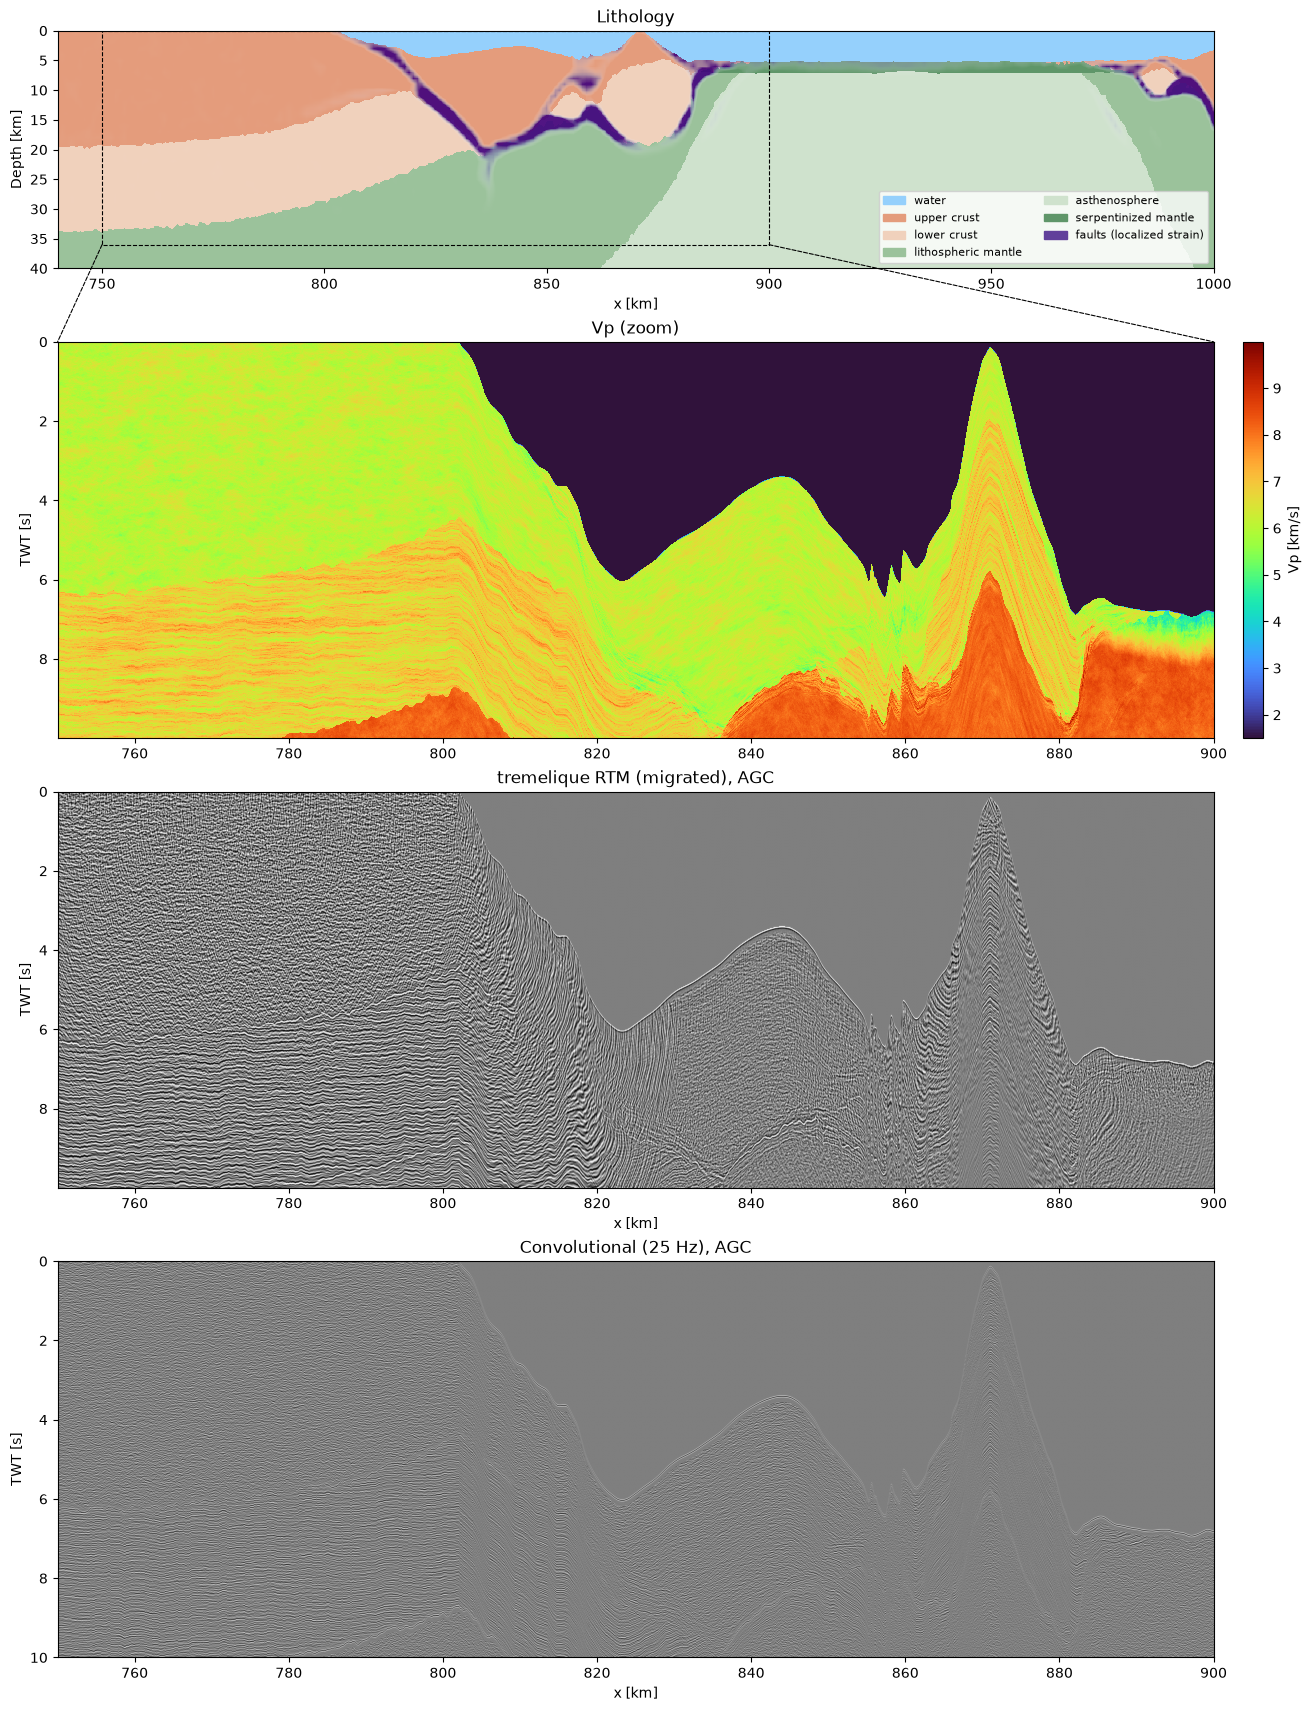

In [14]:
vp_time = depth_to_time(zoom["vp"], twt_zoom, tz)
vp_time[units_time == -1] = np.nan  # below the bottom of the zoom model
fig = plt.figure(figsize=(13, 17), layout="constrained")
# Model panel ~4x wider than tall, as in the model figure; zoom panels taller
grid = fig.add_gridspec(4, 1, height_ratios=[0.6, 1, 1, 1])
# Whole model in depth, with the zoom window
ax_model = fig.add_subplot(grid[0])
plot_units(ax_model, lithology_units(model)[::4, ::4], model["faults"][::4, ::4], extent)
ax_model.add_patch(plt.Rectangle((XZ0 / 1e3, 0), (XZ1 - XZ0) / 1e3, ZZMAX / 1e3,
                                 fill=False, ec="k", ls="--", lw=0.8))  # fmt: skip
ax_model.set_ylabel("Depth [km]")
ax_model.set_xlabel("x [km]")
# Zoom results, in TWT
axes = [fig.add_subplot(grid[1])]
axes += [fig.add_subplot(grid[i], sharex=axes[0]) for i in (2, 3)]
im = axes[0].imshow(vp_time[keep] / 1e3,
                    extent=[XZ0 / 1e3, XZ1 / 1e3, tz[keep][-1], tz[keep][0]],
                    aspect="auto", cmap="turbo", interpolation="nearest")  # fmt: skip
fig.colorbar(im, ax=axes[0], pad=0.01, label="Vp [km/s]")
axes[0].set_title("Vp (zoom)")
axes[0].set_ylabel("TWT [s]")
plot_seismic(migrated, tz, xz, axes[1], "tremelique RTM (migrated), AGC", tlim=tlim)
plot_seismic(conv[:, in_zoom], t, x[in_zoom], axes[2],
             f"Convolutional ({CONV_FPEAK:.0f} Hz), AGC", tlim=tlim)  # fmt: skip
for xc in (XZ0, XZ1):  # link the zoom window to the zoom panels
    fig.add_artist(plt.matplotlib.patches.ConnectionPatch(
        xyA=(xc / 1e3, ZZMAX / 1e3), coordsA=ax_model.transData,
        xyB=(xc / 1e3, tlim[0]), coordsB=axes[0].transData,
        color="k", ls="--", lw=0.8))  # fmt: skip
save(fig, f"zoom_{ZOOM_TAG}_final")

## Limitations and next steps

* No sediments: the scenario has no surface processes; adding them (or
  running Mandyoc with them) would give the strong layered reflections of
  the published sections above the basement.
* Acoustic only (no S waves, no converted waves), zero-offset only.
* The heterogeneity and the fault fabric are statistical: they reproduce
  the texture of real data, not specific reflectors.
* The frequency of the tremelique zoom (~10 Hz peak) is lower than in field
  data; a finer grid raises it at a cost that grows with 1/dx³.

**References**

* Baysal, E., Kosloff, D. D. & Sherwood, J. W. C. (1983). Reverse time
  migration. *Geophysics*, 48(11).
* Christensen, N. I. & Mooney, W. D. (1995). Seismic velocity structure and
  composition of the continental crust. *JGR*, 100(B6).
* Frankel, A. & Clayton, R. W. (1986). Finite difference simulations of
  seismic scattering. *JGR*, 91(B6).
* Gillard, M. et al. (2015, 2016, 2019): seismic observations of
  magma-poor rifted margins (see the PDFs in the Artigos folder).
* Loewenthal, D. et al. (1976). The wave equation applied to migration.
  *Geophysical Prospecting*, 24.